# Warp Bubble Notebook

**What this is.** This notebook takes the warp-drive ideas from the author's handwritten notes, puts the equations into code, and shows what they do in pictures. Every chart has a plain-English caption, and every caption is also printed inside the saved image in `figures/`, so the pictures make sense on their own.

How to read it:
- **f** is the bubble's *shape*. f = 1 means "inside the bubble", where the ship rides along. f = 0 means ordinary, untouched space. The **wall** is the in-between zone where space gets squeezed in front of the ship and stretched behind it.
- All results are reported in ordinary units: metres, seconds, kilograms.
- The author's equations are coded **exactly as written**. Where something looks off, we show "as written" next to "the alternative" instead of quietly changing it.

The full plan is in `docs/warp-bubble-notebook-spec.md`. The math lives in `warp/shapes.py`, with tests in `tests/`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from warp import shapes
from warp.plotting import COLORS, LINESTYLES, phone_figure, save_figure, use_phone_style

use_phone_style()

## 1. The bubble wall: Alcubierre's tanh vs. the cosine wall

All of the exotic negative energy a warp bubble needs sits in its **wall**, and how much it needs depends on how **steep** that wall is: the energy density goes as the steepness squared. Alcubierre's 1994 design uses a tanh-shaped wall whose sharpness is left as a free setting (σ); here we set it to make the wall 1 m thick, the example size Pfenning & Ford used. The author's idea, the **Vorwaller Metric**, is a smooth cosine-shaped wall that can be made much thicker, which makes it far less steep. Here we draw both, with a bubble radius of R = 100 m.

**Yardstick for "thickness".** A tanh wall has soft tails, so its thickness needs a definition. We use the standard one from Pfenning & Ford (1997, eq. 5): the width of a straight ramp that has the same steepness as the wall's middle. That gives Δ ≈ 2/σ, so a 1 m tanh wall has σ = 2 per metre. The author also used σ = 2.0 in the dual-shell design, which matches this yardstick exactly.

The author's cosine wall has a clean edge: it starts at R and ends at exactly R + Δ, so the author's Δ measures the *whole* wall from start to finish. On Pfenning & Ford's steepness yardstick, the same wall counts as 2Δ/π ≈ 0.64 Δ thick. We label the cosine walls with their own Δ and convert wherever the comparison matters.

In [2]:
R = 100.0                              # bubble radius, m
DELTAS = [1.0, 10.0, 100.0, 1000.0]    # The author's cosine wall thicknesses, m
SIGMA = shapes.sigma_for_wall_thickness(1.0, R)   # σ giving a 1 m tanh wall (Pfenning & Ford eq. 5)
print(f"σ for a 1 m Alcubierre wall: {SIGMA:.6f} per metre")

# Radius grid: 5 cm steps everywhere, plus 1 mm steps around the thin walls at 100 m.
r = np.unique(np.concatenate([np.linspace(0.0, 1150.0, 23_001), np.linspace(95.0, 110.0, 15_001)]))

walls = [("Alcubierre tanh, 1 m wall", COLORS["black"], LINESTYLES[0],
          shapes.alcubierre_f(r, R, SIGMA), shapes.alcubierre_df(r, R, SIGMA))]
for (d, color, ls) in zip(DELTAS, ["orange", "sky", "green", "vermillion"], LINESTYLES[1:]):
    walls.append((f"cosine wall, Δ = {d:g} m", COLORS[color], ls,
                  shapes.cosine_wall_f(r, R, d), shapes.cosine_wall_df(r, R, d)))

σ for a 1 m Alcubierre wall: 2.000000 per metre


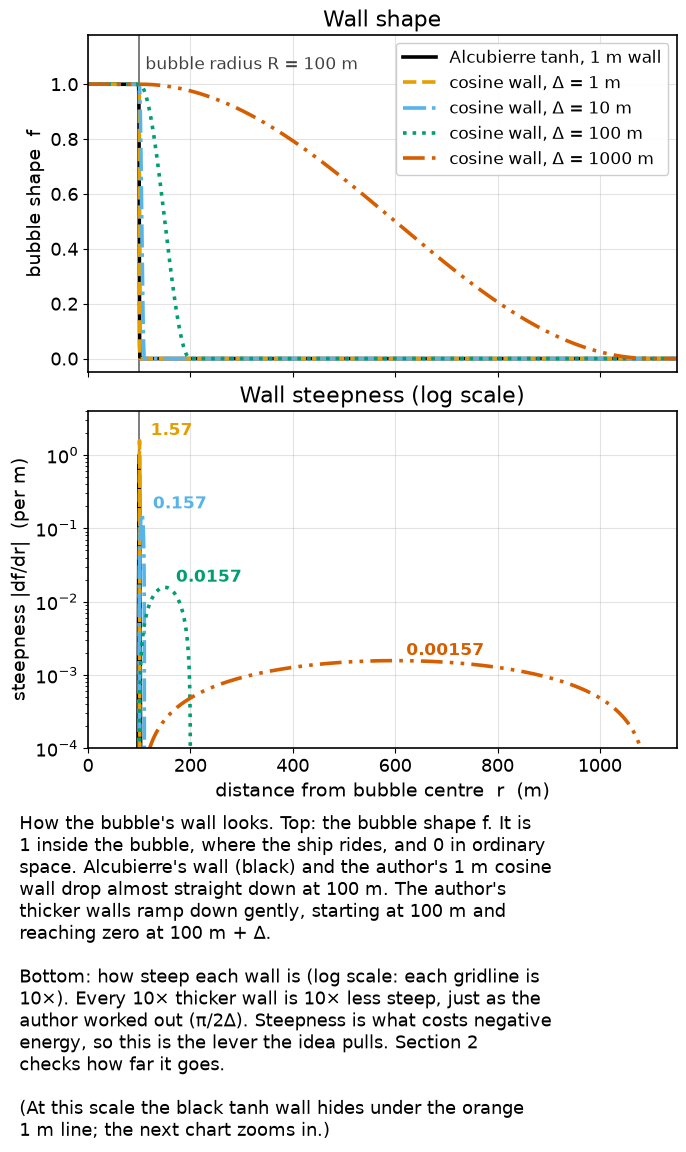

saved 01_wall_shapes.png


In [3]:
fig, (ax_f, ax_df) = phone_figure(2, height_per_row=4.0, sharex=True)

for label, color, ls, f, df in walls:
    ax_f.plot(r, f, color=color, ls=ls, label=label)
    ax_df.plot(r, -df, color=color, ls=ls)

for ax in (ax_f, ax_df):
    ax.axvline(R, color="0.4", lw=1.2, zorder=0)
ax_f.text(R + 12, 1.04, "bubble radius R = 100 m", fontsize=12, color="0.25", va="bottom")

ax_f.set_ylabel("bubble shape  f")
ax_f.set_ylim(-0.05, 1.18)
ax_f.set_title("Wall shape")
ax_f.legend(loc="upper right", frameon=True, framealpha=0.95)

ax_df.set_yscale("log")
ax_df.set_ylim(1e-4, 4)
ax_df.set_ylabel("steepness |df/dr|  (per m)")
ax_df.set_xlabel("distance from bubble centre  r  (m)")
ax_df.set_title("Wall steepness (log scale)")
ax_df.set_xlim(0, 1150)

# Label each cosine wall's peak steepness π/(2Δ) at its midpoint R + Δ/2.
for d, color in zip(DELTAS, ["orange", "sky", "green", "vermillion"]):
    peak = shapes.cosine_wall_max_slope(d)
    x = R + d / 2
    ax_df.annotate(f"{peak:.3g}", (x, peak), xytext=(8, 4), textcoords="offset points",
                   fontsize=12, color=COLORS[color], fontweight="bold")

path = save_figure(fig, "01_wall_shapes", '''
How the bubble's wall looks. Top: the bubble shape f. It is 1 inside the bubble, where the ship rides, and 0 in ordinary space. Alcubierre's wall (black) and the author's 1 m cosine wall drop almost straight down at 100 m. The author's thicker walls ramp down gently, starting at 100 m and reaching zero at 100 m + Δ.

Bottom: how steep each wall is (log scale: each gridline is 10×). Every 10× thicker wall is 10× less steep, just as the author worked out (π/2Δ). Steepness is what costs negative energy, so this is the lever the idea pulls. Section 2 checks how far it goes.

(At this scale the black tanh wall hides under the orange 1 m line; the next chart zooms in.)
''')
plt.show()
print("saved", path.name)

**Checking the author's numbers.** The notes say the steepest point of the cosine wall is π/(2Δ): 1.57 per metre for a 1 m wall and 0.00157 for a 1000 m wall. To check that independently, the table below doesn't use the author's slope formula at all. It measures the slope by finite differences of the wall shape f itself (rise over run between neighbouring points), then finds the steepest spot.

In [4]:
print(f"{'wall Δ (m)':>10}   {'notes: π/(2Δ)':>15}   {'measured max |df/dr|':>21}   {'where (m)':>9}")
for d in DELTAS:
    rr = np.linspace(R, R + d, 1_000_001)
    slope = -np.gradient(shapes.cosine_wall_f(rr, R, d), rr)   # rise over run of f itself
    i = np.argmax(slope)
    print(f"{d:>10g}   {shapes.cosine_wall_max_slope(d):>15.5g}   {slope[i]:>21.5g}   {rr[i]:>9.4g}")

tanh_peak = -shapes.alcubierre_df(R, R, SIGMA)
print(f"\nAlcubierre 1 m tanh wall: max steepness {tanh_peak:.5g} per metre, at r = {R:g} m")

wall Δ (m)     notes: π/(2Δ)    measured max |df/dr|   where (m)
         1            1.5708                  1.5708       100.5
        10           0.15708                 0.15708         105
       100          0.015708                0.015708         150
      1000         0.0015708               0.0015708         600

Alcubierre 1 m tanh wall: max steepness 1 per metre, at r = 100 m


The author's formula is right on every row, and the steepest point is always the middle of the wall (R + Δ/2).

Since the energy density goes as steepness squared, the fair way to compare two walls is to add up steepness² across each one. Pfenning & Ford's total-energy formula also weights each spot by r², so we include that too (the code below does both). This is a preview of Section 2, done for the two 1 m walls only.

In [5]:
from scipy.integrate import quad

def wall_cost(df, lo, hi):
    # ∫ r² (df/dr)² dr across one wall, proportional to that wall's total negative energy (P&F eq. 26).
    value, _ = quad(lambda x: x**2 * df(x)**2, lo, hi, limit=500, epsabs=0, epsrel=1e-11)
    return value

cost_tanh = wall_cost(lambda x: shapes.alcubierre_df(x, R, SIGMA), R - 30, R + 30)   # tails beyond ±30 m are < 1e-50
cost_cos = wall_cost(lambda x: shapes.cosine_wall_df(x, R, 1.0), R, R + 1.0)
COST_RATIO = cost_cos / cost_tanh

print(f"the author's Δ = 1 m wall on the Pfenning & Ford yardstick: {shapes.cosine_wall_pf_thickness(1.0):.3f} m thick")
print(f"energy cost ∫ r² (df/dr)² dr:  tanh {cost_tanh:,.1f} m    cosine {cost_cos:,.1f} m")
print(f"cosine / tanh = {COST_RATIO:.3f}")

the author's Δ = 1 m wall on the Pfenning & Ford yardstick: 0.637 m thick
energy cost ∫ r² (df/dr)² dr:  tanh 6,666.7 m    cosine 12,460.7 m
cosine / tanh = 1.869


The next chart zooms in on the two walls to compare them side by side.

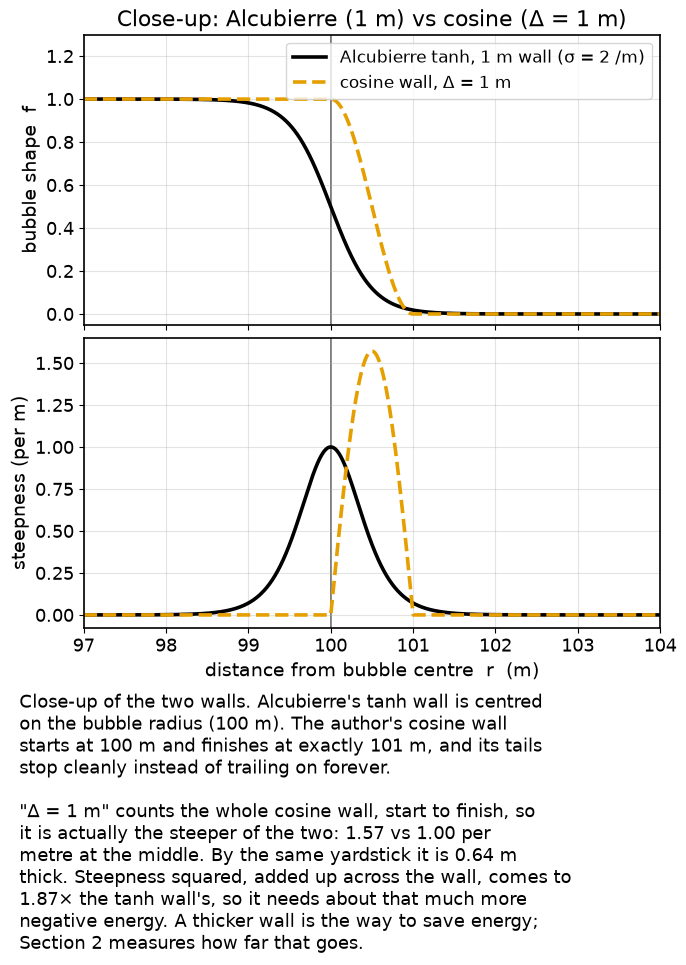

saved 01b_one_metre_walls.png


In [6]:
rz = np.linspace(97.0, 104.0, 7001)
fig, (ax_f, ax_df) = phone_figure(2, height_per_row=3.4, sharex=True)

pairs = [("Alcubierre tanh, 1 m wall (σ = 2 /m)", COLORS["black"], LINESTYLES[0],
          shapes.alcubierre_f(rz, R, SIGMA), shapes.alcubierre_df(rz, R, SIGMA)),
         ("cosine wall, Δ = 1 m", COLORS["orange"], LINESTYLES[1],
          shapes.cosine_wall_f(rz, R, 1.0), shapes.cosine_wall_df(rz, R, 1.0))]
for label, color, ls, f, df in pairs:
    ax_f.plot(rz, f, color=color, ls=ls, label=label)
    ax_df.plot(rz, -df, color=color, ls=ls)

for ax in (ax_f, ax_df):
    ax.axvline(R, color="0.4", lw=1.2, zorder=0)
ax_f.set_ylabel("bubble shape  f")
ax_f.set_ylim(-0.05, 1.3)
ax_f.set_title("Close-up: Alcubierre (1 m) vs cosine (Δ = 1 m)")
ax_f.legend(loc="upper right")
ax_df.set_ylabel("steepness (per m)")
ax_df.set_xlabel("distance from bubble centre  r  (m)")
ax_df.set_xlim(97, 104)

path = save_figure(fig, "01b_one_metre_walls", f'''
Close-up of the two walls. Alcubierre's tanh wall is centred on the bubble radius (100 m). The author's cosine wall starts at 100 m and finishes at exactly 101 m, and its tails stop cleanly instead of trailing on forever.

"Δ = 1 m" counts the whole cosine wall, start to finish, so it is actually the steeper of the two: 1.57 vs 1.00 per metre at the middle. By the same yardstick it is {shapes.cosine_wall_pf_thickness(1.0):.2f} m thick. Steepness squared, added up across the wall, comes to {COST_RATIO:.2f}× the tanh wall's, so it needs about that much more negative energy. A thicker wall is the way to save energy; Section 2 measures how far that goes.
''')
plt.show()
print("saved", path.name)

**What this section shows.** Both walls take the bubble from "inside" (f = 1) to "ordinary space" (f = 0). The author's cosine wall does it with a clean start and finish, and it can be stretched to any thickness. Making it 1000× thicker makes it 1000× less steep, and steepness is what the negative energy depends on. His formula for the steepest slope, π/(2Δ), is exactly right.

Measured fairly, the author's Δ = 1 m wall is a little *thinner* than Alcubierre's 1 m wall (0.64 m on the standard yardstick), so it costs nearly twice as much. That's a labelling difference, not a flaw: the idea is about making the wall thick, and the cosine shape lets you do that cleanly.

One thing to keep in mind for the next section: the author's wall grows *outward* from R, so a 1000 m wall reaches out to 1100 m. A thicker wall is gentler, but it also fills a lot more space. Section 2 adds up the energy over all of that space to see which effect wins.

## 2. How much negative energy? Total energy vs. wall thickness

The energy density goes as steepness squared, so a wall 1000× thicker has an energy density 1,000,000× lower. That's the author's estimate. But a thicker wall also takes up more space, so to get the *total* we have to add up the energy in every cubic metre of the wall. Here we do that for the author's cosine wall, at thicknesses from 1 mm to 100 km, with R = 100 m and the bubble moving at the speed of light.

**The formula, in ordinary units.** The energy density is

  T⁰⁰ = −(c⁴ / 8πG) · (v_s² / 4c²) · ((y² + z²) / r_s²) · (df/dr_s)²

The author's notes write v_s²/4, as Alcubierre's paper does. Both work in units where c = 1. In metres and seconds it becomes v_s²/(4c²), which is what we use. We report the total as a mass, E/c² in kilograms. At speeds other than light speed, multiply every result by (v_s/c)². For example, v_s = 10c means v_s² = 100c², so the energy is 100× larger.

**How we add it up, three independent ways.** (1) The full integral over all of space, done in cylindrical coordinates as the spec asks. (2) A 1-D shortcut: do the angle part by hand (Pfenning & Ford eq. 26) and integrate over radius only. (3) An exact formula for the author's wall, worked out by hand:

  ∫ r² (df/dr)² dr = (π²/8)·R²/Δ + (π²/8)·R + (π²/24 − 1/16)·Δ

If all three agree, we can trust the numbers.

In [7]:
from warp import energy
from warp.plotting import sci_text
from scipy.constants import c

BETA = 1.0                              # v_s / c  (bubble at light speed)
deltas = np.logspace(-3, 5, 49)         # wall thickness Δ: 1 mm to 100 km

def cos_df(d):
    return lambda x: shapes.cosine_wall_df(x, R, d)

mass_2d = np.array([energy.total_mass_cylindrical(cos_df(d), R, R + d, BETA) for d in deltas])
mass_1d = np.array([energy.mass_from_wall_integral(energy.wall_integral(cos_df(d), R, R + d), BETA) for d in deltas])
mass_exact = energy.mass_from_wall_integral(energy.cosine_wall_integral_exact(R, deltas), BETA)

print(f"largest disagreement, full integral vs exact formula: {np.max(np.abs(mass_2d / mass_exact - 1)):.1e}")
print(f"largest disagreement, 1-D shortcut  vs exact formula: {np.max(np.abs(mass_1d / mass_exact - 1)):.1e}")

largest disagreement, full integral vs exact formula: 3.9e-13
largest disagreement, 1-D shortcut  vs exact formula: 7.7e-12


**Checking against published results.** Before trusting the method on the author's wall, we run it on walls whose answers are already known.

In [8]:
def show(label, kg):
    print(f"{label:<52} {abs(kg):.3e} kg  = {abs(kg) / energy.M_SUN:.3f} solar masses")

ramp = energy.wall_integral(lambda x: shapes.pf_ramp_df(x, R, 1.0), R - 0.5, R + 0.5)
show("Pfenning & Ford straight wall, Δ = 1 m (our integral)", energy.mass_from_wall_integral(ramp, BETA))
show("Pfenning & Ford eq. 28, same wall (their formula)", energy.mass_from_wall_integral(R**2 / 1.0 + 1.0 / 12, BETA))
tanh_1m = energy.total_mass_cylindrical(lambda x: shapes.alcubierre_df(x, R, SIGMA), R - 30, R + 30, BETA)
show("Alcubierre tanh wall, 1 m (full integral)", tanh_1m)
show("cosine wall, Δ = 1 m (full integral)", energy.total_mass_cylindrical(cos_df(1.0), R, R + 1, BETA))

Pfenning & Ford straight wall, Δ = 1 m (our integral) 1.122e+30 kg  = 0.564 solar masses
Pfenning & Ford eq. 28, same wall (their formula)    1.122e+30 kg  = 0.564 solar masses


Alcubierre tanh wall, 1 m (full integral)            7.481e+29 kg  = 0.376 solar masses
cosine wall, Δ = 1 m (full integral)                 1.398e+30 kg  = 0.703 solar masses


Our integral reproduces Pfenning & Ford's own eq. 28 exactly. Their text says "on the order of a quarter of a solar mass", while eq. 28 gives 0.56, a factor of about 2. A guess at the cause: dividing by the Sun's Schwarzschild radius (2GM/c²) instead of GM/c² would give exactly 0.28. Either way it's the same order of magnitude, which is all they claimed. The 1 m cosine wall needs about 1.9× the tanh wall's energy, as Section 1 found.

Now the main question: how does the total change as the wall gets thicker?

In [9]:
# Slopes on the log-log plot: d ln|M| / d ln Δ
log_d, log_m = np.log10(deltas), np.log10(np.abs(mass_2d))
SLOPE_THIN = np.polyfit(log_d[deltas <= 0.1], log_m[deltas <= 0.1], 1)[0]
SLOPE_THICK = np.polyfit(log_d[deltas >= 1e4], log_m[deltas >= 1e4], 1)[0]
D_BEST = energy.cosine_wall_optimal_delta(R)
M_BEST = abs(energy.mass_from_wall_integral(energy.cosine_wall_integral_exact(R, D_BEST), BETA))
M_1M = abs(energy.mass_from_wall_integral(energy.cosine_wall_integral_exact(R, 1.0), BETA))

print(f"slope for thin walls  (Δ ≤ 0.1 m):  {SLOPE_THIN:+.3f}")
print(f"slope for thick walls (Δ ≥ 10 km):  {SLOPE_THICK:+.3f}")
print(f"lowest energy at Δ = {D_BEST:.1f} m: {M_BEST:.3e} kg = {M_BEST / energy.M_SUN:.4f} solar masses "
      f"= {M_BEST / energy.M_JUPITER:.1f} Jupiter masses")
print(f"that is {M_1M / M_BEST:.1f}× less than the 1 m wall")

slope for thin walls  (Δ ≤ 0.1 m):  -1.000
slope for thick walls (Δ ≥ 10 km):  +0.987
lowest energy at Δ = 188.1 m: 2.857e+28 kg = 0.0144 solar masses = 15.0 Jupiter masses
that is 49.0× less than the 1 m wall


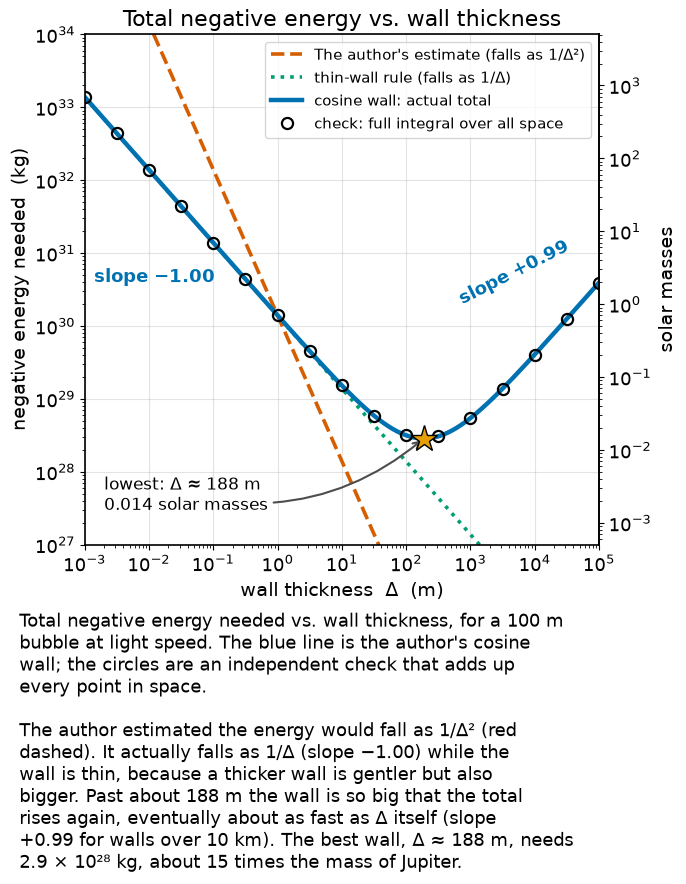

saved 02_energy_vs_thickness.png


In [10]:
d_fine = np.logspace(-3, 5, 801)
m_fine = np.abs(energy.mass_from_wall_integral(energy.cosine_wall_integral_exact(R, d_fine), BETA))
thin_rule = np.abs(energy.mass_from_wall_integral(np.pi**2 / 8 * R**2 / d_fine, BETA))   # (π²/8) R²/Δ

fig, ax = phone_figure(1, height_per_row=6.0)
ax.loglog(d_fine, M_1M / d_fine**2, color=COLORS["vermillion"], ls="--", label="The author's estimate (falls as 1/Δ²)")
ax.loglog(d_fine, thin_rule, color=COLORS["green"], ls=":", label="thin-wall rule (falls as 1/Δ)")
ax.loglog(d_fine, m_fine, color=COLORS["blue"], ls="-", lw=3.2, label="cosine wall: actual total")
ax.loglog(deltas[::3], np.abs(mass_2d[::3]), "o", color="black", mfc="none", ms=8, mew=1.6,
          label="check: full integral over all space")
ax.plot(D_BEST, M_BEST, marker="*", ms=20, color=COLORS["orange"], mec="black", zorder=5)
ax.annotate(f"lowest: Δ ≈ {D_BEST:.0f} m\n{M_BEST / energy.M_SUN:.3f} solar masses",
            (D_BEST, M_BEST), xytext=(2e-3, 3e27), textcoords="data", ha="left", fontsize=12,
            arrowprops=dict(arrowstyle="->", color="0.3", lw=1.5, connectionstyle="arc3,rad=0.25"))
ax.text(1.4e-3, 4e30, f"slope {SLOPE_THIN:.2f}".replace("-", "−"), fontsize=13, color=COLORS["blue"],
        fontweight="bold")
ax.text(6e2, 2.0e30, f"slope +{SLOPE_THICK:.2f}", fontsize=13, color=COLORS["blue"], fontweight="bold", rotation=27)

ax.set_xlim(1e-3, 1e5)
ax.set_ylim(1e27, 1e34)
ax.set_xlabel("wall thickness  Δ  (m)")
ax.set_ylabel("negative energy needed  (kg)")
ax.set_title("Total negative energy vs. wall thickness")
ax.legend(loc="upper right", fontsize=11)
sec = ax.secondary_yaxis("right", functions=(lambda m: m / energy.M_SUN, lambda s: s * energy.M_SUN))
sec.set_ylabel("solar masses")

path = save_figure(fig, "02_energy_vs_thickness", f'''
Total negative energy needed vs. wall thickness, for a 100 m bubble at light speed. The blue line is the author's cosine wall; the circles are an independent check that adds up every point in space.

The author estimated the energy would fall as 1/Δ² (red dashed). It actually falls as 1/Δ (slope −{abs(SLOPE_THIN):.2f}) while the wall is thin, because a thicker wall is gentler but also bigger. Past about {D_BEST:.0f} m the wall is so big that the total rises again, eventually about as fast as Δ itself (slope +{SLOPE_THICK:.2f} for walls over 10 km). The best wall, Δ ≈ {D_BEST:.0f} m, needs {sci_text(M_BEST)} kg, about {M_BEST / energy.M_JUPITER:.0f} times the mass of Jupiter.
''')
plt.show()
print("saved", path.name)

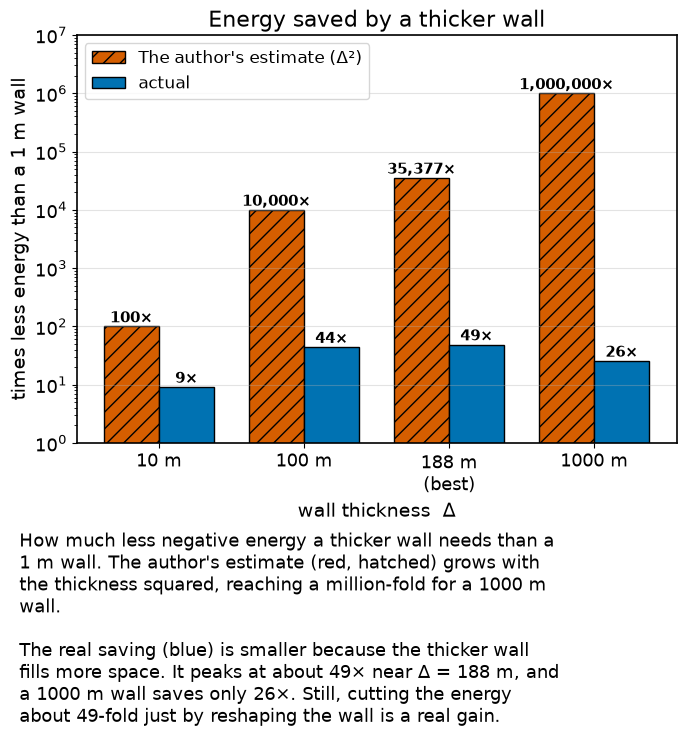

saved 02b_savings_vs_estimate.png


In [11]:
compare = [10.0, 100.0, D_BEST, 1000.0]
labels = ["10 m", "100 m", f"{D_BEST:.0f} m\n(best)", "1000 m"]
estimate_saving = np.array([d**2 for d in compare])          # The author's 1/Δ² estimate, relative to 1 m
actual_saving = np.array([M_1M / abs(energy.mass_from_wall_integral(energy.cosine_wall_integral_exact(R, d), BETA))
                          for d in compare])

fig, ax = phone_figure(1, height_per_row=5.2)
x = np.arange(len(compare))
w = 0.38
b1 = ax.bar(x - w / 2, estimate_saving, w, color=COLORS["vermillion"], hatch="//", edgecolor="black",
            label="The author's estimate (Δ²)")
b2 = ax.bar(x + w / 2, actual_saving, w, color=COLORS["blue"], edgecolor="black", label="actual")
for bars in (b1, b2):
    for bar in bars:
        v = bar.get_height()
        ax.annotate(f"{v:,.0f}×", (bar.get_x() + bar.get_width() / 2, v), xytext=(0, 3),
                    textcoords="offset points", ha="center", fontsize=11, fontweight="bold")
ax.set_yscale("log")
ax.set_ylim(1, 1e7)
ax.set_xticks(x, labels)
ax.set_xlabel("wall thickness  Δ")
ax.set_ylabel("times less energy than a 1 m wall")
ax.set_title("Energy saved by a thicker wall")
ax.legend(loc="upper left")
ax.grid(axis="x", visible=False)

path = save_figure(fig, "02b_savings_vs_estimate", f'''
How much less negative energy a thicker wall needs than a 1 m wall. The author's estimate (red, hatched) grows with the thickness squared, reaching a million-fold for a 1000 m wall.

The real saving (blue) is smaller because the thicker wall fills more space. It peaks at about {actual_saving[2]:.0f}× near Δ = {D_BEST:.0f} m, and a 1000 m wall saves only {actual_saving[3]:.0f}×. Still, cutting the energy about {actual_saving[2]:.0f}-fold just by reshaping the wall is a real gain.
''')
plt.show()
print("saved", path.name)

**The answer, in two sentences.** The energy *density* does fall as 1/Δ², just as the author said, but a thicker wall also fills more space: while the wall is thinner than the bubble, its volume grows as Δ, so the total falls only as 1/Δ (Pfenning & Ford's result, slope −1). Because the author's wall grows outward from the bubble, once it is thicker than the bubble itself its volume grows faster than the density falls, so the total bottoms out near Δ ≈ 1.9 R (188 m for this bubble) and then climbs, eventually about as fast as Δ itself.

**What holds up.** For the *total amount* of negative energy, thickening the wall helps, up to about the bubble's own size. The best cosine wall needs about 49× less than a 1 m wall. The sweet spot scales with the bubble: Δ_best ≈ 1.88 R.

**What this section does not cover.**
- *Steady bubble.* These numbers are for a bubble at constant speed. The energy-density formula itself still holds at every instant for the author's time-dependent designs (it depends only on how the bubble's shape varies in space), but those designs change the stresses and the curvature of space-time, which a later section works out.
- *The quantum inequality points the other way.* Pfenning & Ford's main objection isn't the total amount. It's how strong negative energy can be and for how long, the author's |ρ|·τ⁴ ≤ constant. A thicker wall lowers the strength |ρ| (as 1/Δ²), but it also bends space more gently, and the time window the test is allowed to use grows with the bending length (τ grows as Δ). So |ρ|·τ⁴ *grows* as Δ². By their test a thick wall is harder to allow, not easier. That is how they conclude the wall can be at most about 100 Planck lengths thick (their eq. 23). Whether their assumptions hold for a real warp drive (a free scalar field, and their choice of how long to sample the energy) is the genuine open question, and a good one for the author to dig into. Section 3 puts numbers on it.

In [12]:
# The author's notes quote E ≈ −10⁴⁵ kg. What would it take to get that with this formula?
target = 1e45
k = energy.KG_PER_METRE / 12 * np.pi**2 / 8 * R**2          # thin-wall rule at v_s = c: M ≈ k / Δ
print(f"at v_s = c, a cosine wall would need Δ ≈ {k / target:.1e} m to reach 10^45 kg")
print(f"with a 1 m wall, it would need v_s ≈ {np.sqrt(target / M_1M):.1e} c")
print(f"for comparison: 10^45 joules is a mass of {1e45 / c**2:.1e} kg; this section's best wall needs {M_BEST:.1e} kg")

at v_s = c, a cosine wall would need Δ ≈ 1.4e-15 m to reach 10^45 kg
with a 1 m wall, it would need v_s ≈ 2.7e+07 c
for comparison: 10^45 joules is a mass of 1.1e+28 kg; this section's best wall needs 2.9e+28 kg


**About the −10⁴⁵ kg figure in the author's notes.** With a 100 m bubble, that much energy would need either a wall about 10⁻¹⁵ m thin (roughly the size of a proton) or a speed of tens of millions of times light speed. We don't know which assumptions went into that number, so it's a good question to ask the author. Two possibilities worth asking about, both guesses:
- Pfenning & Ford quote the Milky Way's mass as "2 × 10⁴⁵ **grams**" (their eq. 30). Grams vs. kilograms is an easy slip.
- 10⁴⁵ **joules** is about 1 × 10²⁸ kg, close to this section's best-wall answer (2.9 × 10²⁸ kg). Joules vs. kilograms is another easy slip.

It may also come from a different bubble size, speed or wall thickness than the ones used here.

## 3. The quantum inequality: how long can negative energy last?

Quantum physics does allow negative energy, but with a catch: the stronger it is, the shorter it can last. The author's notes write this as |ρ|·τ⁴ ≤ constant, and that is exactly the right form: it is the Ford–Roman *quantum inequality*. Here we put in the real constant and test the cosine wall against it. This is the test Pfenning & Ford used to argue that warp-bubble walls must be fantastically thin.

**The rule.** For the simplest quantum field, a negative energy density of strength |ρ| can last only about τ, where

  |ρ| · τ⁴ ≤ 3ħ / (32π² c³) ≈ 3.7 × 10⁻⁶² J·s⁴/m³

(ħ is the reduced Planck constant.) Strictly, it limits the energy density averaged over a time window of width τ, as seen by someone floating past.

**The catch for curved space.** The rule was proven for flat space. Near a warp-bubble wall, space is curved, so the rule is only trusted over time windows shorter than the time light takes to cross the curvature length r_min (the shortest bending length of space-time anywhere in the wall). Following Pfenning & Ford we use a window of τ = α·r_min/c with α = 0.1.

**How we test, step by step.**
1. Find the strongest negative energy anywhere in the wall (on the bubble's "equator", where the wall is steepest).
2. Compute r_min from the *full* curvature of space-time, all 20 independent components of the Riemann tensor, everywhere in the wall (`warp/curvature.py`).
3. Follow a real observer drifting through the strongest spot, and average the energy they see over the window τ, exactly as the rule prescribes.
4. Compare with the most negative average the rule allows.

**The choices favour the warp design.** For r_min we take the largest curvature *anywhere* in the wall, even at points the observer never visits. That gives the shortest window, and a shorter window loosens the limit. Pfenning & Ford used one curvature component of a simplified straight wall. Our worst-case choice is about 7× looser than their estimate. Using only the curvature along the observer's own path would be about 1.7× looser than theirs. The next cell prints both, and the headline numbers use the looser one.

In [13]:
from warp import quantum

print(f"quantum-inequality constant 3ħ/(32π²c³) = {quantum.QI_CONSTANT:.3e} J·s⁴/m³")
print(f"Planck length = {quantum.PLANCK_LENGTH:.4e} m\n")

ALPHA = 0.1
def cos_funcs(d):
    return (lambda x: shapes.cosine_wall_f(x, R, d), lambda x: shapes.cosine_wall_df(x, R, d),
            lambda x: shapes.cosine_wall_ddf(x, R, d))

qi = {d: quantum.qi_check(BETA, ALPHA, *cos_funcs(d), R, R + d) for d in [1.0, D_BEST, 1000.0]}
print(f"{'wall Δ':>9} {'strongest |ρ| (J/m³)':>21} {'may last':>10} {'test window':>12} {'over the limit by':>18}")
for d, res in qi.items():
    print(f"{d:>7.0f} m {abs(res.peak_density):>21.2e} {res.allowed_duration:>8.1e} s {res.tau:>10.1e} s {res.violation:>18.1e}")

w1 = quantum.qi_check(BETA, ALPHA, *cos_funcs(1.0), R, R + 1.0, curvature="worldline")
print(f"\n1 m wall using only the curvature along the observer's path: over the limit by {w1.violation:.1e} "
      f"({w1.violation / qi[1.0].violation:.1f}× tighter than the worst-case choice above)")

quantum-inequality constant 3ħ/(32π²c³) = 3.718e-62 J·s⁴/m³
Planck length = 1.6163e-35 m



   wall Δ  strongest |ρ| (J/m³)   may last  test window  over the limit by
      1 m              2.97e+42  1.1e-26 s    1.5e-10 s            4.1e+64
    188 m              8.40e+37  1.5e-25 s    2.8e-08 s            1.4e+69
   1000 m              2.97e+36  3.3e-25 s    1.5e-07 s            3.9e+70

1 m wall using only the curvature along the observer's path: over the limit by 1.7e+65 (4.1× tighter than the worst-case choice above)


**Reading the table.** For a 1 m wall the negative energy is so strong that the rule lets it last only about 10⁻²⁶ seconds. But the wall holds it in place for the whole test window, about 10⁻¹⁰ seconds (and in fact much longer, the whole time the bubble takes to pass). Because the limit goes as τ⁴, a factor of about 10¹⁶ in time becomes a factor of about 10⁶⁴ in the inequality. Thicker walls make it worse, not better: they lower the strength (as 1/Δ²) but stretch the window (as Δ), so the overshoot grows as Δ².

The next cell checks how much these conclusions depend on the choices we made: the window size α and the bubble's speed.

In [14]:
f1, df1, ddf1 = cos_funcs(1.0)
print("1 m cosine wall, how far over the limit:")
for beta in [1.0, 10.0]:
    row = "  ".join(f"α = {a:<4g}: {quantum.qi_check(beta, a, f1, df1, ddf1, R, R + 1.0).violation:.1e}"
                    for a in [1.0, 0.1, 0.01])
    print(f"  v_s = {beta:>4g} c   {row}")

v_needed = np.sqrt(qi[1.0].violation)        # overshoot falls as 1/(v_s/c)²
d_ok = 1.0 / np.sqrt(qi[1.0].violation)      # overshoot grows as Δ²; Δ = 1 m is the reference
print(f"\nto pass (at α = 0.1), a 1 m wall would need v_s ≈ {v_needed:.0e} c,")
print(f"or, at v_s = c, a wall thinner than about {d_ok:.0e} m = {d_ok / quantum.PLANCK_LENGTH:.0f} Planck lengths")

1 m cosine wall, how far over the limit:


  v_s =    1 c   α = 1   : 4.0e+68  α = 0.1 : 4.1e+64  α = 0.01: 4.1e+60


  v_s =   10 c   α = 1   : 4.0e+66  α = 0.1 : 4.1e+62  α = 0.01: 4.1e+58

to pass (at α = 0.1), a 1 m wall would need v_s ≈ 2e+32 c,
or, at v_s = c, a wall thinner than about 5e-33 m = 307 Planck lengths


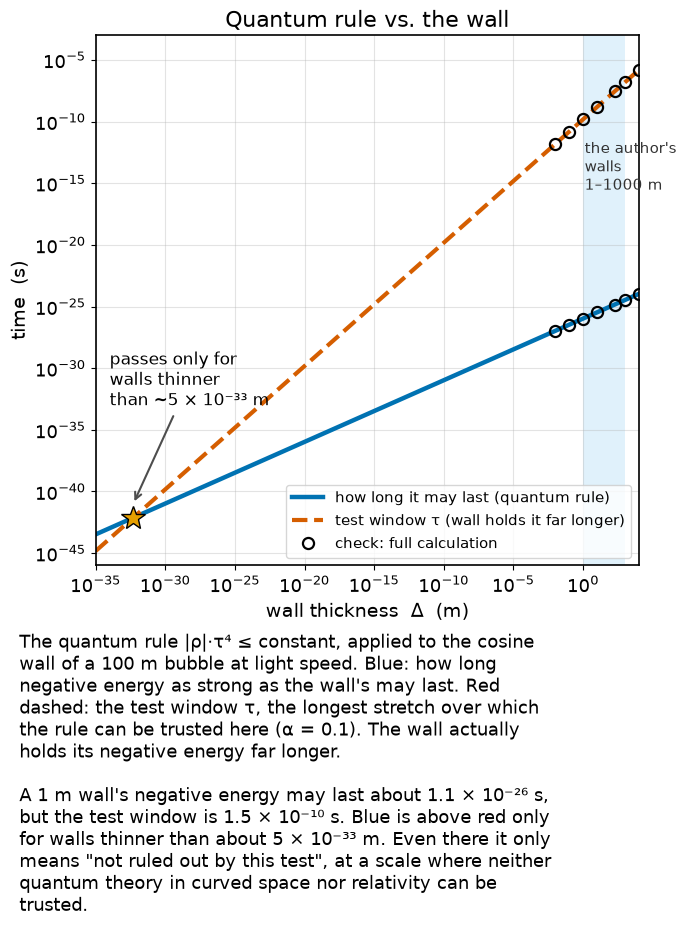

saved 03_quantum_inequality.png


In [15]:
# Durations vs wall thickness. Both are exact formulas for the cosine wall, valid at any Δ:
#   strongest |ρ| = (c⁴/8πG)(β²/4)(π/2Δ)²   (equator, mid-wall)
#   r_min = 1/√(β² π²/(2Δ²))                 (largest curvature: on the axis at the outer edge;
#                                             tested for β ≥ 0.5, and scale-free because f = f' = 0 there)
# Circles: the full numerical calculation at a few thicknesses, as a check.
from scipy.constants import c as C_LIGHT

d_axis = np.logspace(-35, 4, 400)
rho_peak = energy.ENERGY_DENSITY_SCALE * BETA**2 / 4 * (np.pi / (2 * d_axis))**2
may_last = quantum.allowed_duration(rho_peak)
window = ALPHA * np.sqrt(2) * d_axis / (np.pi * BETA) / C_LIGHT
D_OK = d_ok

check_d = [1e-2, 1e-1, 1.0, 10.0, D_BEST, 1e3, 1e4]
checks = [quantum.qi_check(BETA, ALPHA, *cos_funcs(d), R, R + d) for d in check_d]

fig, ax = phone_figure(1, height_per_row=6.2)
ax.loglog(d_axis, may_last, color=COLORS["blue"], lw=3.2, label="how long it may last (quantum rule)")
ax.loglog(d_axis, window, color=COLORS["vermillion"], ls="--", lw=3.0, label="test window τ (wall holds it far longer)")
ax.loglog(check_d, [r.allowed_duration for r in checks], "o", color="black", mfc="none", ms=8, mew=1.6,
          label="check: full calculation")
ax.loglog(check_d, [r.tau for r in checks], "o", color="black", mfc="none", ms=8, mew=1.6)
ax.plot(D_OK, quantum.allowed_duration(energy.ENERGY_DENSITY_SCALE * BETA**2 / 4 * (np.pi / (2 * D_OK))**2), marker="*",
        ms=18, color=COLORS["orange"], mec="black", zorder=5)
ax.annotate(f"passes only for\nwalls thinner\nthan ~{sci_text(D_OK, 0)} m", (D_OK, 1e-41), xytext=(1e-34, 1e-33),
            fontsize=12, arrowprops=dict(arrowstyle="->", color="0.3", lw=1.5))
ax.axvspan(1.0, 1e3, color=COLORS["sky"], alpha=0.18, lw=0)
ax.text(1.3, 3e-16, "the author's\nwalls\n1–1000 m", fontsize=11, color="0.2")

ax.set_xlim(1e-35, 1e4)
ax.set_ylim(1e-46, 1e-3)
ax.set_xlabel("wall thickness  Δ  (m)")
ax.set_ylabel("time  (s)")
ax.set_title("Quantum rule vs. the wall")
ax.legend(loc="lower right", fontsize=11)

path = save_figure(fig, "03_quantum_inequality", f'''
The quantum rule |ρ|·τ⁴ ≤ constant, applied to the cosine wall of a 100 m bubble at light speed. Blue: how long negative energy as strong as the wall's may last. Red dashed: the test window τ, the longest stretch over which the rule can be trusted here (α = 0.1). The wall actually holds its negative energy far longer.

A 1 m wall's negative energy may last about {sci_text(qi[1.0].allowed_duration)} s, but the test window is {sci_text(qi[1.0].tau)} s. Blue is above red only for walls thinner than about {sci_text(D_OK, 0)} m. Even there it only means "not ruled out by this test", at a scale where neither quantum theory in curved space nor relativity can be trusted.
''')
plt.show()
print("saved", path.name)

**What holds up.**
- The author's form of the rule, |ρ|·τ⁴ ≤ constant, is exactly right; the constant is 3ħ/(32π²c³).
- The pulsed design was aimed at the right weak spot. The rule *does* allow stronger negative energy for shorter times, so "keep each burst brief" is the natural move. The numbers are extreme: a burst as strong as this 1 m wall's negative energy would have to be over within about 10⁻²⁶ seconds. Switching on and off also bends space-time in its own way, which changes the test window and brings requirements of its own. So the pulsed and dual-shell designs need their own analysis, which comes in a later section.

**What the numbers say.** By this test a thick wall is harder to allow, not easier. The overshoot grows as Δ², from about 10⁶⁴ at 1 m to about 10⁷⁰ at 1000 m. Sections 2 and 3 pull in opposite directions: thicker walls need less total negative energy, while the quantum rule demands thinner ones. That tension is Pfenning & Ford's whole argument.

**What is still genuinely open.** The rule used here holds for *every* quantum state of the simplest kind of field (a free scalar field), so choosing a clever state doesn't escape it. What is genuinely open:
1. Fields with interactions, or unusual couplings to gravity. Some of these are known to get around the simplest versions of these rules.
2. How the rule itself changes in strongly curved space. Here we assumed the flat-space version holds over windows shorter than the curvature time, as Pfenning & Ford did.
3. Whether the whole picture, quantum fields living on a classical curved space-time, still holds near the Planck scale.

That is where a new idea would have to break through, and it's a great set of questions to dig into.